# Notebook 06 — Final Training and the Locked Test Evaluation

**Track A · Soccer Event Transformer · Identity × Context project**

| Item | Content |
|---|---|
| **Research question (project level)** | When identity and context point to different actions, what does a trained model do? This notebook trains and evaluates the final model that is later analysed mechanistically. |
| **Purpose of this notebook** | (1) Train the frozen configuration (2 layers, 2 heads, K = 16, T300) with five new seeds. (2) Train the restricted baselines (context-only, identity-only, role-only) and refit B1–B4 at the frozen configuration. (3) Check the pre-defined selection gates on validation. (4) Choose the primary checkpoint by a fixed rule. (5) Measure the identity value on validation. (6) Evaluate every model once on the test split. |

**Test-set discipline.** The configuration was frozen in notebook 05. The test split is used only in Section 6, after all validation decisions have been recorded, and each model is evaluated on it once.


In [1]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every Track A notebook)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# PROJECT_DIR holds code (src/), data artifacts, runs, results and the release.
PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
# DATASET_PATH is the prepared research dataset (one row per on-ball event).
DATASET_PATH = Path(os.environ.get("TRACK_A_DATASET", str(PROJECT_DIR / "data" / "cleaned_dataset.parquet")))
# RUN_MODE = "full"  -> real research runs (use this for every reported number)
# RUN_MODE = "smoke" -> tiny code check only; outputs go to PROJECT_DIR/smoke and are NOT results
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
(PROJECT_DIR / "src").mkdir(exist_ok=True)
(PROJECT_DIR / "tests").mkdir(exist_ok=True)

# Data-audit artifacts are cheap and always produced in full mode.
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
# Training runs, results and figures are separated by run mode so a smoke check can never
# overwrite or be confused with a research result.
OUTPUT_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
RUNS_DIR = OUTPUT_DIR / "runs"
RESULTS_DIR = OUTPUT_DIR / "results"
FIGURES_DIR = OUTPUT_DIR / "figures"
for folder in [ARTIFACTS_DIR, RUNS_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATASET_PATH:", DATASET_PATH, "| exists:", DATASET_PATH.exists())

Mounted at /content/drive
Colab: True | RUN_MODE: full
PROJECT_DIR: /content/drive/MyDrive/soccer_mi/track_a
DATASET_PATH: /content/drive/MyDrive/soccer_mi/track_a/data/cleaned_dataset.parquet | exists: True


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib
from scipy.stats import spearmanr
import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    # CPU training is correct but slow (about 0.55 s per step on one core, ~40-70 min per run).
    # It is allowed only on explicit request, and the device is recorded in every run's results.
    if os.environ.get("TRACK_A_ALLOW_CPU") != "1":
        raise RuntimeError("BLOCKED: full-mode training on CPU is very slow. Use a GPU runtime, "
                           "or set TRACK_A_ALLOW_CPU=1 to train on CPU deliberately.")
    print("WARNING: training on CPU by explicit request (TRACK_A_ALLOW_CPU=1).")
MANIFEST_PATH = OUTPUT_DIR / "manifests" / "experiment_manifest.jsonl"

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()
train_counts = data.count_train_events_per_player(events)
event_train_count = events["player_id"].map(train_counts).fillna(0).to_numpy()

with open(RESULTS_DIR / "04_selected_hyperparameters.json") as handle:
    selected_hyperparameters = json.load(handle)
LEARNING_RATE = selected_hyperparameters["learning_rate"]
WEIGHT_DECAY = selected_hyperparameters["weight_decay"]
EPOCH_BUDGET = selected_hyperparameters["epoch_budget"]
print(f"Selected in notebook 04: learning rate {LEARNING_RATE:g}, weight decay {WEIGHT_DECAY:g}, epoch budget {EPOCH_BUDGET}")

def transformer_config(seed, encoding, context_length=32, n_layers=4, n_heads=4, d_ff=512, use_groups=None):
    model = {"n_layers": n_layers, "n_heads": n_heads, "d_model": 128, "d_ff": d_ff}
    if use_groups is not None:
        model["use_groups"] = list(use_groups)
    return {"model_type": "transformer", "encoding": encoding, "possession_features": "pre_action",
            "context_length": context_length, "stride": 8, "seed": seed, "model": model,
            "training": {"learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY, "max_epochs": EPOCH_BUDGET}}

def run(config, keep_every_epoch=False):
    run_bundle = training.prepare_data(events, ARTIFACTS_DIR, config["encoding"], config["possession_features"],
                                       config["context_length"], config["stride"], DEVICE, RUN_MODE)
    result = training.train_run(config, run_bundle, RUNS_DIR, MANIFEST_PATH, keep_every_epoch=keep_every_epoch)
    return RUNS_DIR / result["run_name"]

def run_seeds(seeds, **settings):
    return [run(transformer_config(seed, **settings)) for seed in seeds]

Selected in notebook 04: learning rate 0.0003, weight decay 0.1, epoch budget 30


In [3]:
frozen_path = OUTPUT_DIR / "config" / "frozen_config.json"
if not frozen_path.exists():
    raise RuntimeError("BLOCKED: no frozen configuration. Run notebook 05 first.")
with open(frozen_path) as handle:
    frozen = json.load(handle)
FINAL_SEEDS = [100, 101, 102, 103, 104]      # disjoint from the development seeds 0-2 used for tuning
BASELINE_SEEDS = [100, 101, 102]

def final_config(seed, use_groups=None):
    model = dict(frozen["model"])
    if use_groups is not None:
        model["use_groups"] = list(use_groups)
    return {"model_type": "transformer", "encoding": frozen["encoding"],
            "possession_features": frozen["possession_features"], "context_length": frozen["context_length"],
            "stride": frozen["stride"], "seed": seed, "model": model,
            "training": {"learning_rate": frozen["training"]["learning_rate"],
                         "weight_decay": frozen["training"]["weight_decay"],
                         "max_epochs": frozen["training"]["max_epochs"]}}

final_bundle = training.prepare_data(events, ARTIFACTS_DIR, frozen["encoding"], frozen["possession_features"],
                                     frozen["context_length"], frozen["stride"], DEVICE, RUN_MODE)
print("Frozen configuration:", json.dumps({k: frozen[k] for k in ["encoding", "context_length", "model", "training"]}))

Frozen configuration: {"encoding": "T300", "context_length": 16, "model": {"n_layers": 2, "n_heads": 2, "d_model": 128, "d_ff": 512}, "training": {"learning_rate": 0.0003, "weight_decay": 0.1, "max_epochs": 30, "batch_size": 256, "warmup_fraction": 0.05, "min_lr_ratio": 0.1, "grad_clip": 1.0, "patience": 5}}


## 1. Final training: 5 seeds of the frozen configuration (B8)

**Why new seeds?** Seeds 0–2 were used while choosing settings. Reporting those runs would slightly favour the chosen configuration (it was chosen partly because those seeds did well). The five reported models use seeds 100–104, which played no part in any decision. Every-epoch checkpoints are kept for these runs, so their training trajectories remain available.

In [4]:
final_runs = []
for seed in FINAL_SEEDS:
    final_runs.append(run(final_config(seed), keep_every_epoch=True))
final_summary = analysis.seed_summary(final_runs)
final_summary.round(4)

[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  1 | train loss 1.6157 | val NLL 1.0872 | val acc 0.5859 | val macro-F1 0.4891 | 6s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  2 | train loss 0.9955 | val NLL 0.9572 | val acc 0.6045 | val macro-F1 0.5213 | 5s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  3 | train loss 0.9309 | val NLL 0.9316 | val acc 0.6138 | val macro-F1 0.5446 | 6s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  4 | train loss 0.9053 | val NLL 0.9249 | val acc 0.6104 | val macro-F1 0.5522 | 5s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  5 | train loss 0.8882 | val NLL 0.9097 | val acc 0.6200 | val macro-F1 0.5497 | 5s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  6 | train loss 0.8741 | val NLL 0.9109 | val acc 0.6205 | val macro-F1 0.5599 | 5s
[tra

,run,seed,best epoch,epochs run,diverged,val NLL,val accuracy,val macro-F1,train NLL,minutes
0,transformer_T300_pre_action_L2_H2_D128_F512_K1...,100,8,13,False,0.9070,0.6216,0.5606,0.8312,1.1104
1,transformer_T300_pre_action_L2_H2_D128_F512_K1...,101,7,12,False,0.9048,0.6222,0.5563,0.8448,0.9927
2,transformer_T300_pre_action_L2_H2_D128_F512_K1...,102,8,13,False,0.9060,0.6221,0.5617,0.8337,1.0945
3,transformer_T300_pre_action_L2_H2_D128_F512_K1...,103,6,11,False,0.9077,0.6212,0.5568,0.8579,0.9357
4,transformer_T300_pre_action_L2_H2_D128_F512_K1...,104,7,12,False,0.9067,0.6199,0.5545,0.8457,1.0061


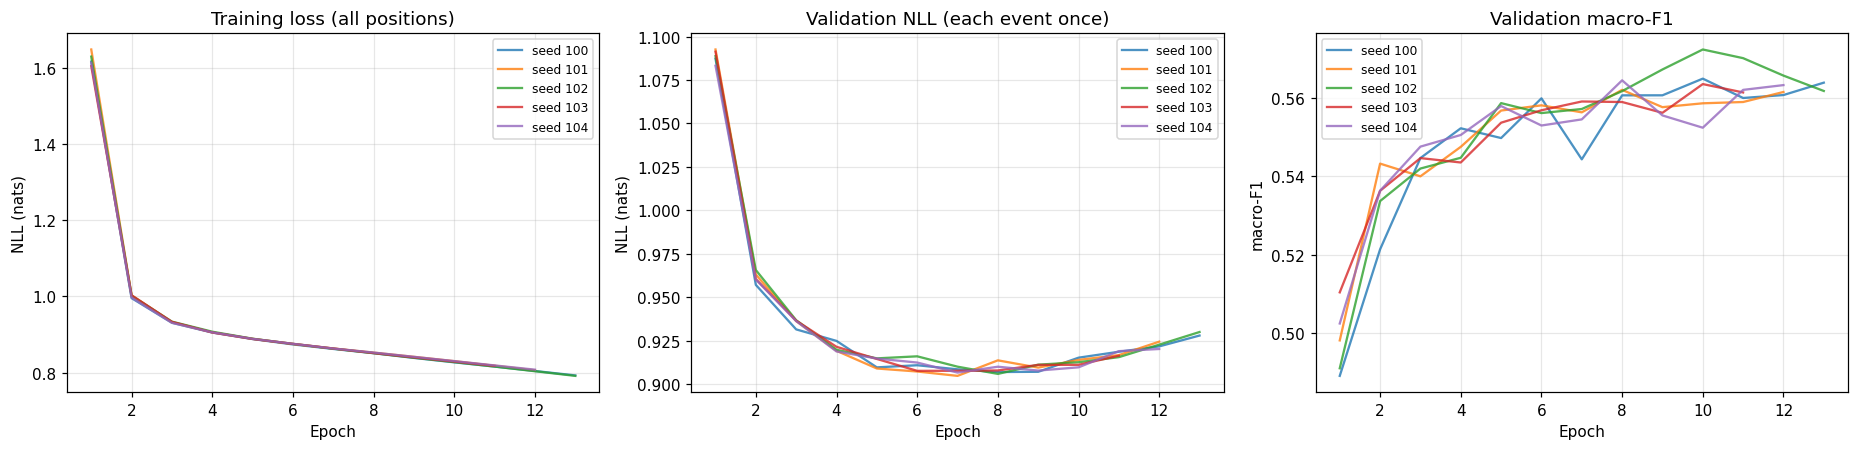

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for run_dir, seed in zip(final_runs, FINAL_SEEDS):
    history = analysis.load_history(run_dir)
    axes[0].plot(history["epoch"], history["train_loss"], alpha=0.8, label=f"seed {seed}")
    axes[1].plot(history["epoch"], history["val_nll"], alpha=0.8, label=f"seed {seed}")
    axes[2].plot(history["epoch"], history["val_macro_f1"], alpha=0.8, label=f"seed {seed}")
axes[0].set_title("Training loss (all positions)")
axes[1].set_title("Validation NLL (each event once)")
axes[2].set_title("Validation macro-F1")
for ax, label in zip(axes, ["NLL (nats)", "NLL (nats)", "macro-F1"]):
    ax.set_xlabel("Epoch")
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_final_training_curves.png", bbox_inches="tight")
plt.show()

**What the figure shows.** Training loss, validation NLL and validation macro-F1 per epoch for the five final seeds (100–104).

**Observation.** The five runs are very close to each other. Validation NLL reaches its minimum between epochs 6 and 8 and rises slowly afterwards, while the training loss keeps falling; the runs stop after 11–13 epochs. The best validation NLL of the five seeds lies between 0.9048 and 0.9077 (SD 0.0011), and the training NLL at the best checkpoint between 0.831 and 0.858. Macro-F1 keeps increasing slightly for a few epochs after the NLL minimum.

**Interpretation.** Training is stable and reproducible across seeds; no run diverged. The seed spread of about 0.001 nats is the training noise against which later differences have to be judged. Because the checkpoint is chosen on NLL, the retained models are the best-calibrated point of each run rather than the point of highest macro-F1.

**What cannot be concluded.** Similar curves show that the training procedure is stable; they do not show that the five models compute their predictions in the same way internally.

## 2. Restricted baselines and refitted baselines at the frozen configuration

The restricted Transformers use **exactly** the frozen architecture and training settings; only the information they receive differs.

| Model | Receives | Question |
|---|---|---|
| **B5 context-only** | competition, space, time, game state, history, position — **no player, team or role** | How well can actions be predicted without identity? |
| **B6 identity-only** | player, team, role, position — **no context** | How well from identity alone? |
| **B7 role-only** | everything except player and team | How much do player and team add beyond role? **B7 vs B8 is the identity-value comparison.** |

B1–B3 (non-neural) are refitted on the training split with the frozen encoding; B4 (MLP) is trained at the frozen encoding and context length with the learning rate selected in notebook 04.

In [6]:
GROUPS_B5 = ["competition", "space", "time", "state", "history"]
GROUPS_B6 = ["player", "team", "role"]
GROUPS_B7 = ["role", "competition", "space", "time", "state", "history"]
restricted_runs = {
    "B5 context-only": [run(final_config(seed, GROUPS_B5)) for seed in BASELINE_SEEDS],
    "B6 identity-only": [run(final_config(seed, GROUPS_B6)) for seed in BASELINE_SEEDS],
    "B7 role-only": [run(final_config(seed, GROUPS_B7)) for seed in BASELINE_SEEDS],
}

with open(RESULTS_DIR / "04_b4_comparison.json") as handle:
    mlp_learning_rate = json.load(handle)["selected_mlp_lr"]
b4_runs = []
for seed in [0, 1, 2]:
    b4_config = {"model_type": "mlp", "encoding": frozen["encoding"], "possession_features": frozen["possession_features"],
                 "context_length": frozen["context_length"], "stride": frozen["stride"], "seed": seed,
                 "model": {"n_layers": 0, "n_heads": 0, "d_model": 128, "d_ff": 0, "hidden": 512, "n_previous": 3},
                 "training": {"learning_rate": mlp_learning_rate, "weight_decay": frozen["training"]["weight_decay"],
                              "max_epochs": frozen["training"]["max_epochs"]}}
    b4_runs.append(run(b4_config))
neural_runs = {"B8 Transformer (final)": final_runs, "B4 MLP": b4_runs, **restricted_runs}

[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.1_s100] epoch  1 | train loss 1.6120 | val NLL 1.1037 | val acc 0.5812 | val macro-F1 0.4994 | 4s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.1_s100] epoch  2 | train loss 1.0234 | val NLL 0.9777 | val acc 0.5967 | val macro-F1 0.5059 | 4s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.1_s100] epoch  3 | train loss 0.9588 | val NLL 0.9470 | val acc 0.6073 | val macro-F1 0.5419 | 6s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.1_s100] epoch  4 | train loss 0.9355 | val NLL 0.9296 | val acc 0.6087 | val macro-F1 0.5396 | 4s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.1_s100] epoch  5 | train loss 0.9207 | val NLL 0.9205 | val acc 0.6148 | val macro-F1 0.5407 | 4s
[tran

### 2.1 Non-neural baselines B1–B3 at the frozen encoding

Fitted on training events only; smoothing strengths are the ones selected on validation in notebook 02. Their validation predictions are computed now; test predictions only after the unlock in Section 6.

In [7]:
%%writefile src/evaluation.py
"""
src/evaluation.py — evaluation helpers for the final models (notebook 06).
"""
import json
from pathlib import Path

import numpy as np
import pandas as pd

import src.baselines as baselines
import src.metrics as metrics


def fit_non_neural_baselines(features, targets, train_rows, alphas, max_iter=1000, checkpoint_path=None):
    """Fit B1a, B1b, B2, B3 on training rows. Returns a dict of predict functions (rows -> logits)."""
    train_targets = targets[train_rows]
    fitted_lr = baselines.fit_logistic_regression(features, targets, list_categorical(features),
                                                  ["x_norm", "y_norm", "dt", "t_poss"], train_rows, max_iter=max_iter,
                                                  checkpoint_path=checkpoint_path)

    def predict_b1a(rows):
        return baselines.predict_class_prior(train_targets, len(rows))

    def predict_b1b(rows):
        return baselines.predict_zone_prior(features["zone"][train_rows], train_targets, features["zone"][rows],
                                            alphas["B1b zone prior"])

    def predict_b2(rows):
        return baselines.predict_markov(features["prev_action"][train_rows], features["zone"][train_rows], train_targets,
                                        features["prev_action"][rows], features["zone"][rows], alphas["B2 Markov"])

    def predict_b3(rows):
        return baselines.predict_logistic_regression(fitted_lr, features, rows)

    return {"B1a class prior": predict_b1a, "B1b zone prior": predict_b1b,
            "B2 Markov": predict_b2, "B3 logistic regression": predict_b3}, fitted_lr


def list_categorical(features):
    return [name for name in ["player", "team", "role", "competition", "zone", "period", "minute_bin", "score_diff",
                              "poss_len", "possession_flag", "prev_action", "prev_outcome",
                              "prev_end_zone", "same_player_as_prev"] if name in features]


def compare_runs_to_fixed(nll_runs, nll_fixed, match_ids, n_resamples=2000, seed=0):
    """Multi-seed model (nll_runs [n_seeds, n_events]) vs a deterministic baseline (nll_fixed [n_events])."""
    difference = nll_runs.mean(axis=0) - nll_fixed
    interval = metrics.match_bootstrap_mean(difference, match_ids, n_resamples, seed)
    all_seeds_lower = bool((nll_runs.mean(axis=1) < nll_fixed.mean()).all())
    return {"difference": interval["mean"], "ci_low": interval["ci_low"], "ci_high": interval["ci_high"],
            "all_seeds_lower": all_seeds_lower,
            "better_beyond_noise": bool(interval["ci_high"] < 0 and all_seeds_lower)}


def stratum_labels(events):
    """Named subgroups used for stratified test evaluation. Each value is a pandas Series of labels."""
    x_metres = events["x_norm"].to_numpy() * 120
    y_metres = events["y_norm"].to_numpy() * 80
    zone_band = np.where(x_metres < 40, "own third", np.where(x_metres < 80, "middle third", "final third"))
    in_box = (x_metres >= 102) & (y_metres >= 18) & (y_metres <= 62)
    zone_band = np.where(in_box, "opponent penalty box", zone_band)

    minute = events["minute"].to_numpy()
    time_band = np.where(events["period"].to_numpy() > 2, "extra time",
                         np.where(minute < 15, "0-15'", np.where(minute < 30, "15-30'", np.where(minute < 45, "30-45'",
                         np.where(minute < 60, "45-60'", np.where(minute < 75, "60-75'", "75'+"))))))

    score = events["score_diff_idx"].to_numpy() - 3
    score_state = np.where(score < 0, "losing", np.where(score == 0, "level", "winning"))

    previous_length = events["prev_poss_len"].to_numpy()
    possession_band = np.where(previous_length == 21, "first event of period",
                               np.where(previous_length <= 2, "early in spell (0-2)",
                               np.where(previous_length <= 9, "mid spell (3-9)", "long spell (10+)")))
    actor_team_changed = np.where(events["team_change"].to_numpy() == 1, "acting team changed", "same acting team")
    coupled = np.where(events["coupled_with_prev"].to_numpy() == 1, "same-moment (coupled) event", "genuine sequence event")
    return {"zone": zone_band, "time": time_band, "score state": score_state,
            "possession spell": possession_band, "turnover of actor team": actor_team_changed, "coupled": coupled}


def frequency_labels(events, train_counts, team_vocabulary):
    count = events["player_id"].map(train_counts).fillna(0).to_numpy()
    player_band = np.where(count < 100, "<100 train events (incl. unseen)",
                           np.where(count < 300, "100-299", np.where(count < 1000, "300-999", ">=1000")))
    known_team = events["team_id"].astype(str).isin(set(team_vocabulary.keys())).to_numpy()
    team_status = np.where(known_team, "team seen in training", "team unseen in training")
    return player_band, team_status

Writing src/evaluation.py


In [8]:
import src.evaluation as evaluation
importlib.reload(evaluation)
with open(PROJECT_DIR / "results" / "baselines_validation.json") as handle:
    alphas = json.load(handle)["selected_alpha"]

final_encoding = data.load_encoding(ARTIFACTS_DIR / "encodings" / frozen["encoding"])
final_features, _ = data.encode_features(events, final_encoding, frozen["possession_features"])
train_rows = np.where(events["split"] == "train")[0]
val_rows = np.where(events["split"] == "val")[0]
if RUN_MODE == "smoke":
    val_rows = np.sort(final_bundle["views"]["val"]["event_rows"])
    train_rows = train_rows[:20000]

start_time = time.time()
b3_checkpoint = OUTPUT_DIR / "artifacts_b3" / f"{frozen['encoding']}_{frozen['possession_features']}.joblib"
non_neural_predict, fitted_lr = evaluation.fit_non_neural_baselines(final_features, targets, train_rows, alphas,
                                                                    max_iter=1000 if RUN_MODE == "full" else 50,
                                                                    checkpoint_path=b3_checkpoint)
print(f"B1-B3 fitted in {time.time() - start_time:.0f} s | logistic regression iterations: {fitted_lr['iterations']}"
      f" | converged: {fitted_lr['converged']}")
non_neural_val_nll = {}
for name, predict in non_neural_predict.items():
    non_neural_val_nll[name] = metrics.per_event_nll(predict(val_rows), targets[val_rows])

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

B1-B3 fitted in 241 s | logistic regression iterations: 418 | converged: True


## 3. Selection gates on validation (defined before training)

| Gate | Requirement | Origin of the threshold |
|---|---|---|
| Baseline improvement | B8 beats every one of B1–B4 beyond noise on validation | decision rule of notebook 04 |
| No divergence | no final seed diverged | objective |
| Stability | seed standard deviation of validation NLL is **reported**; no pass/fail threshold is imposed, because no justified threshold exists | reported only |
| Class coverage | every class with more than 500 validation events has F1 > 0 in every seed | convention of this study (500 ≈ 0.7% of validation events, so that an F1 of exactly 0 cannot be explained by a handful of events) |
| Size cap | at most 4 layers and 8 heads | keeps exhaustive later analysis feasible |

In [9]:
val_rows_sorted, b8_val_nll = analysis.condition_event_nll(final_runs, targets)
val_match_ids = match_ids[val_rows_sorted]
gate_rows = []
for name, nll_fixed in non_neural_val_nll.items():
    fixed_sorted = nll_fixed[np.argsort(val_rows)][np.searchsorted(np.sort(val_rows), val_rows_sorted)]
    comparison = evaluation.compare_runs_to_fixed(b8_val_nll, fixed_sorted, val_match_ids)
    gate_rows.append({"baseline": name, "B8 - baseline NLL": comparison["difference"],
                      "CI": f"[{comparison['ci_low']:+.4f}, {comparison['ci_high']:+.4f}]",
                      "B8 better beyond noise": comparison["better_beyond_noise"]})
b4_comparison = analysis.compare_conditions(final_runs, b4_runs, targets, match_ids)
gate_rows.append({"baseline": "B4 MLP", "B8 - baseline NLL": b4_comparison["difference_a_minus_b"],
                  "CI": f"[{b4_comparison['difference_ci_low']:+.4f}, {b4_comparison['difference_ci_high']:+.4f}]",
                  "B8 better beyond noise": b4_comparison["a_better_beyond_noise"]})
baseline_gate_table = pd.DataFrame(gate_rows).set_index("baseline")

val_support = np.bincount(targets[val_rows_sorted], minlength=15)
coverage_failures = []
for run_dir in final_runs:
    per_class = analysis.load_final_results(run_dir)["val_metrics"]["per_class_f1"]
    for class_id in range(15):
        if val_support[class_id] > 500 and per_class[class_id] == 0:
            coverage_failures.append((run_dir.name, data.ACTION_NAMES[class_id]))

gates = {
    "baseline improvement (all of B1-B4)": bool(baseline_gate_table["B8 better beyond noise"].all()),
    "no divergence": bool(not final_summary["diverged"].any()),
    "class coverage (PROVISIONAL)": len(coverage_failures) == 0,
    "size cap": frozen["model"]["n_layers"] <= 4 and frozen["model"]["n_heads"] <= 8,
}
print("Validation NLL across the 5 final seeds: mean", round(final_summary["val NLL"].mean(), 4),
      "| SD", round(final_summary["val NLL"].std(ddof=1), 4), "(reported, no threshold)")
for gate, passed in gates.items():
    print(f"{'PASS' if passed else 'FAIL'}  {gate}")
if coverage_failures:
    print("Classes with zero F1:", coverage_failures)
baseline_gate_table

Validation NLL across the 5 final seeds: mean 0.9065 | SD 0.0011 (reported, no threshold)
PASS  baseline improvement (all of B1-B4)
PASS  no divergence
PASS  class coverage (PROVISIONAL)
PASS  size cap


,B8 - baseline NLL,CI,B8 better beyond noise
baseline,,,
B1a class prior,-1.068113,"[-1.0945, -1.0419]",True
B1b zone prior,-0.875393,"[-0.8969, -0.8534]",True
B2 Markov,-0.504398,"[-0.5181, -0.4892]",True
B3 logistic regression,-0.144263,"[-0.1510, -0.1372]",True
B4 MLP,-0.040950,"[-0.0442, -0.0378]",True


**RESULT.** All gates pass. The final Transformer is better than every baseline beyond noise on validation: by 0.1443 nats against logistic regression (B3, 95% CI 0.1372 to 0.1510) and by 0.0410 nats against the MLP over the last four events (B4, 95% CI 0.0378 to 0.0442). The mean validation NLL over the five seeds is 0.9065 (SD 0.0011).

**Interpretation.** The frozen Transformer extracts predictive information that neither frequency tables, a linear model of the current event, nor an MLP with a fixed short history can extract. This is the minimum requirement for studying its internal computation.

**Limitation.** The gates establish a minimum standard; they do not compare the model with other published models or with larger models.

## 4. Primary checkpoint (rule fixed in advance)

The **primary** checkpoint used for the later analysis is the final seed with the **median** validation NLL — not the best one. Choosing the best seed would pick a model that is partly lucky; the median seed is the most typical outcome of the training procedure. The other four seeds are kept as replicates.

In [10]:
ordered = final_summary.sort_values("val NLL").reset_index(drop=True)
primary_run_name = ordered.loc[len(ordered) // 2, "run"]
primary_seed = int(ordered.loc[len(ordered) // 2, "seed"])
primary_run_dir = RUNS_DIR / primary_run_name
replicate_run_dirs = [run_dir for run_dir in final_runs if run_dir.name != primary_run_name]
print(f"Primary checkpoint: seed {primary_seed} ({primary_run_name}), validation NLL {ordered.loc[len(ordered) // 2, 'val NLL']:.4f}")
print("Validation NLL by seed (sorted):", [round(v, 4) for v in ordered["val NLL"]])

Primary checkpoint: seed 104 (transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s104), validation NLL 0.9067
Validation NLL by seed (sorted): [0.9048, 0.906, 0.9067, 0.907, 0.9077]


## 5. Identity value on validation

**Definition.** *Identity value* = validation NLL of the role-only model B7 minus that of the full model B8, per event, averaged. Positive means that adding player and team information lowers prediction error. It is reported overall and by how often the acting player appears in training. This is a **predictive** comparison between two separately trained models; it is not used to select anything, and it says nothing about *how* the model uses identity.

In [11]:
player_band, team_status = evaluation.frequency_labels(events, train_counts, final_encoding["team_vocabulary"])

def identity_value_table(runs_full, runs_restricted, row_labels):
    rows = []
    groups = ["all events"] + sorted(set(row_labels[val_rows_sorted]))
    for group in groups:
        mask = None if group == "all events" else (row_labels == group)
        comparison = analysis.compare_conditions(runs_restricted, runs_full, targets, match_ids, mask)
        rows.append({"group": group, "events": comparison["n_events"],
                     "restricted NLL": comparison["nll_a_mean"], "full model NLL": comparison["nll_b_mean"],
                     "value (restricted - full)": comparison["difference_a_minus_b"],
                     "95% CI": f"[{comparison['difference_ci_low']:+.4f}, {comparison['difference_ci_high']:+.4f}]"})
    return pd.DataFrame(rows).set_index("group")

identity_value_val = identity_value_table(final_runs, restricted_runs["B7 role-only"], player_band)
identity_value_team = identity_value_table(final_runs, restricted_runs["B7 role-only"], team_status)
print("Identity value by player training frequency (B7 role-only vs B8 full), validation:")
display(identity_value_val.round(4))
print("Identity value by whether the acting team was seen in training, validation:")
display(identity_value_team.round(4))

context_value = analysis.compare_conditions(restricted_runs["B6 identity-only"], final_runs, targets, match_ids)
role_plus_context = analysis.compare_conditions(restricted_runs["B5 context-only"], final_runs, targets, match_ids)
print(f"B6 identity-only - B8: {context_value['difference_a_minus_b']:+.4f}  (value of context given identity)")
print(f"B5 context-only - B8: {role_plus_context['difference_a_minus_b']:+.4f}  (value of player+team+role given context)")

Identity value by player training frequency (B7 role-only vs B8 full), validation:


,events,restricted NLL,full model NLL,value (restricted - full),95% CI
group,,,,,
all events,68003,0.8863,0.9065,-0.0201,"[-0.0229, -0.0174]"
100-299,20693,0.8862,0.9048,-0.0187,"[-0.0235, -0.0145]"
300-999,10644,0.8764,0.8938,-0.0174,"[-0.0245, -0.0111]"
<100 train events (incl. unseen),33419,0.8860,0.9094,-0.0234,"[-0.0271, -0.0198]"
>=1000,3247,0.9226,0.9279,-0.0053,"[-0.0087, -0.0019]"


Identity value by whether the acting team was seen in training, validation:


,events,restricted NLL,full model NLL,value (restricted - full),95% CI
group,,,,,
all events,68003,0.8863,0.9065,-0.0201,"[-0.0229, -0.0174]"
team seen in training,58506,0.8869,0.9069,-0.0200,"[-0.0233, -0.0167]"
team unseen in training,9497,0.8826,0.9037,-0.0211,"[-0.0247, -0.0167]"


B6 identity-only - B8: +0.7462  (value of context given identity)
B5 context-only - B8: -0.0080  (value of player+team+role given context)


**RESULT.** The identity value on validation is negative: the role-only model B7 reaches 0.8863 against 0.9065 for the full model, a difference of −0.0201 nats (95% CI −0.0229 to −0.0174). The value is negative in every player-frequency band: −0.0234 for players with fewer than 100 training events (including unseen players), −0.0187 for 100–299, −0.0174 for 300–999 and −0.0053 for players with at least 1,000 training events. It is also negative for events of teams unseen in training (−0.0211) and of teams seen in training (−0.0200). The context-only model B5 is also better than the full model (by 0.0080 nats), while the identity-only model B6 is much worse (by 0.7462 nats).

**Interpretation.** Under this configuration, adding player and team inputs to the role-only model increases prediction error. The effect is present even for events whose player has no dedicated embedding (fewer than 100 training events, index 0 under T300) and for teams not seen in training, i.e. where the identity inputs carry no learned information about the acting player or team. The disadvantage is therefore not confined to events with a learned identity vector. The result is consistent with the identity inputs making the model fit the training matches more closely, but the experiment does not identify the cause. Context alone carries almost all of the predictive information; identity alone is far weaker.

**Consequence for the research question.** The frozen model does not use player identity to predictive advantage. This does not rule out that identity influences its predictions, but it means that an identity-versus-context analysis of this model studies a model in which identity inputs lower predictive performance.

**What cannot be concluded.** The comparison does not show how the model uses identity, or what it does when identity and context conflict. It also inherits the actor-selection caveat: the acting player is partly determined by the kind of event recorded.

In [12]:
validation_report = {
    "frozen_config": frozen, "final_seeds": FINAL_SEEDS, "gates": gates,
    "baseline_comparison": baseline_gate_table.reset_index().to_dict(orient="records"),
    "coverage_failures": coverage_failures,
    "seed_summary": final_summary.to_dict(orient="records"),
    "primary_run": primary_run_name, "primary_seed": primary_seed,
    "replicate_runs": [run_dir.name for run_dir in replicate_run_dirs],
    "identity_value_by_player_band": identity_value_val.reset_index().to_dict(orient="records"),
    "identity_value_by_team_status": identity_value_team.reset_index().to_dict(orient="records"),
    "b6_minus_b8": context_value, "b5_minus_b8": role_plus_context,
    "run_mode": RUN_MODE,
}
training.save_json(RESULTS_DIR / "06_validation_report.json", validation_report)
print("Validation decisions written before the test split is unlocked.")

Validation decisions written before the test split is unlocked.


## 6. The locked test evaluation (performed once)

All decisions above were made on validation data and recorded. The test split is then unlocked, every model predicts every test event once, and the predictions are saved.

In [13]:
test_prediction_dir = RESULTS_DIR / "test_predictions"
test_prediction_dir.mkdir(parents=True, exist_ok=True)
test_done_flag = RESULTS_DIR / "06_test_results.json"

test_logits = {}      # model name -> list of [n_test_events, 15] arrays (one per seed)
if test_done_flag.exists():
    print("Test evaluation already performed; reloading saved predictions (no new evaluation).")
    for file in sorted(test_prediction_dir.glob("*.npz")):
        stored = np.load(file, allow_pickle=True)
        test_logits.setdefault(str(stored["model"]), []).append(stored["logits"])
        test_rows = stored["event_rows"]
else:
    training.unlock_test_split(final_bundle, OUTPUT_DIR, events)
    for model_name, run_dirs in neural_runs.items():
        run_bundle = training.prepare_data(events, ARTIFACTS_DIR, frozen["encoding"], frozen["possession_features"],
                                           frozen["context_length"], frozen["stride"], DEVICE, RUN_MODE)
        if not run_bundle["test_unlocked"]:
            training.unlock_test_split(run_bundle, OUTPUT_DIR, events)
        for run_dir in run_dirs:
            model = training.load_trained_model(run_dir, run_bundle)
            logits, _, test_rows = training.predict_view(model, run_bundle, "test")
            test_logits.setdefault(model_name, []).append(logits)
            np.savez_compressed(test_prediction_dir / f"{run_dir.name}.npz", logits=logits, event_rows=test_rows,
                                model=model_name, run=run_dir.name)
    for model_name, predict in non_neural_predict.items():
        logits = predict(test_rows)
        test_logits[model_name] = [logits]
        np.savez_compressed(test_prediction_dir / f"{model_name.replace(' ', '_')}.npz", logits=logits,
                            event_rows=test_rows, model=model_name, run=model_name)
test_targets = targets[test_rows]
test_match_ids = match_ids[test_rows]
print("Test events scored:", len(test_rows), "| models:", list(test_logits))

Test events scored: 65009 | models: ['B8 Transformer (final)', 'B4 MLP', 'B5 context-only', 'B6 identity-only', 'B7 role-only', 'B1a class prior', 'B1b zone prior', 'B2 Markov', 'B3 logistic regression']


### 6.1 Headline test results

For multi-seed models: the mean over seeds, the seed standard deviation, and a 95% match-bootstrap confidence interval of the NLL computed on per-event NLL averaged over seeds. Macro-F1 intervals are computed for the primary seed (B8) or the single fit (non-neural baselines).

In [14]:
headline_rows = []
model_order = ["B1a class prior", "B1b zone prior", "B2 Markov", "B3 logistic regression", "B4 MLP",
               "B6 identity-only", "B5 context-only", "B7 role-only", "B8 Transformer (final)"]
for model_name in model_order:
    seed_logits = test_logits[model_name]
    seed_metrics = [metrics.compute_metrics(logits, test_targets) for logits in seed_logits]
    event_nll = np.mean([metrics.per_event_nll(logits, test_targets) for logits in seed_logits], axis=0)
    nll_ci = metrics.match_bootstrap_mean(event_nll, test_match_ids, n_resamples=2000 if RUN_MODE == "full" else 50)
    row = {"model": model_name, "seeds": len(seed_logits),
           "NLL": np.mean([m["nll"] for m in seed_metrics]),
           "NLL seed SD": np.std([m["nll"] for m in seed_metrics], ddof=1) if len(seed_metrics) > 1 else 0.0,
           "NLL 95% CI": f"[{nll_ci['ci_low']:.4f}, {nll_ci['ci_high']:.4f}]",
           "accuracy": np.mean([m["accuracy"] for m in seed_metrics]),
           "top-3": np.mean([m["top3_accuracy"] for m in seed_metrics]),
           "top-5": np.mean([m["top5_accuracy"] for m in seed_metrics]),
           "macro-F1": np.mean([m["macro_f1"] for m in seed_metrics]),
           "ECE": np.mean([m["ece"] for m in seed_metrics])}
    headline_rows.append(row)
headline_table = pd.DataFrame(headline_rows).set_index("model")

primary_position = [run_dir.name for run_dir in final_runs].index(primary_run_name)
primary_logits = test_logits["B8 Transformer (final)"][primary_position]
primary_metrics = metrics.compute_metrics(primary_logits, test_targets)
primary_f1_ci = metrics.match_bootstrap_macro_f1(primary_logits, test_targets, test_match_ids,
                                                 n_resamples=500 if RUN_MODE == "full" else 20)
print(f"Primary checkpoint (seed {primary_seed}) on test: NLL {primary_metrics['nll']:.4f}, accuracy {primary_metrics['accuracy']:.4f}, "
      f"macro-F1 {primary_f1_ci['mean']:.4f} [{primary_f1_ci['ci_low']:.4f}, {primary_f1_ci['ci_high']:.4f}], ECE {primary_metrics['ece']:.4f}")
headline_table.round(4)

Primary checkpoint (seed 104) on test: NLL 0.9153, accuracy 0.6171, macro-F1 0.5538 [0.5466, 0.5607], ECE 0.0223


,seeds,NLL,NLL seed SD,NLL 95% CI,accuracy,top-3,top-5,macro-F1,ECE
model,,,,,,,,,
B1a class prior,1,2.0202,0.0000,"[1.9945, 2.0468]",0.2971,0.7163,0.8167,0.0305,0.0052
B1b zone prior,1,1.8188,0.0000,"[1.7946, 1.8444]",0.3227,0.7504,0.8702,0.1327,0.0061
B2 Markov,1,1.4332,0.0000,"[1.4108, 1.4564]",0.4489,0.8434,0.9459,0.3611,0.0048
B3 logistic regression,1,1.0649,0.0000,"[1.0451, 1.0843]",0.5753,0.9198,0.9830,0.5090,0.0122
B4 MLP,3,0.9524,0.0027,"[0.9396, 0.9652]",0.6027,0.9390,0.9920,0.5413,0.0306
B6 identity-only,3,1.7462,0.0245,"[1.6718, 1.8234]",0.3757,0.7778,0.8916,0.1830,0.0694
B5 context-only,3,0.9103,0.0014,"[0.8967, 0.9232]",0.6197,0.9458,0.9936,0.5547,0.0181
B7 role-only,3,0.8960,0.0005,"[0.8827, 0.9093]",0.6238,0.9466,0.9942,0.5632,0.0200
B8 Transformer (final),5,0.9158,0.0013,"[0.9035, 0.9283]",0.6161,0.9445,0.9937,0.5580,0.0238


**RESULT.** On the 65,009 test events, the final Transformer (B8) reaches an NLL of 0.9158 (95% CI 0.9035 to 0.9283, seed SD 0.0013), accuracy 0.6161, top-3 accuracy 0.9445, macro-F1 0.5580 and ECE 0.0238. The ladder of baselines reproduces the validation ordering: class prior 2.0202, zone prior 1.8188, Markov 1.4332, logistic regression 1.0649, MLP 0.9524. The restricted Transformers with the same architecture give 1.7462 (identity-only), 0.9103 (context-only) and 0.8960 (role-only).

**Interpretation.**

* The Transformer improves on logistic regression by about 0.15 nats and on the MLP by about 0.04 nats on unseen matches, so the gains seen on validation carry over to the test split.
* The role-only model (B7) has lower test NLL than the full model, together with slightly higher accuracy (0.6238) and macro-F1 (0.5632). The negative identity value found on validation is confirmed on data not used for any decision (identity value −0.0199 nats).
* Context carries most of the information: the context-only model (0.9103) is close to the best models, the identity-only model (1.7462) is only moderately better than the zone prior.
* Accuracy is dominated by the three most frequent classes; macro-F1 and the per-class results below show performance on rare actions.

**What cannot be concluded.** The test numbers describe these 35 matches from this data source. The confidence intervals cover match sampling, not differences in competitions or annotation outside this dataset.

### 6.2 Per-class performance, confusion and calibration

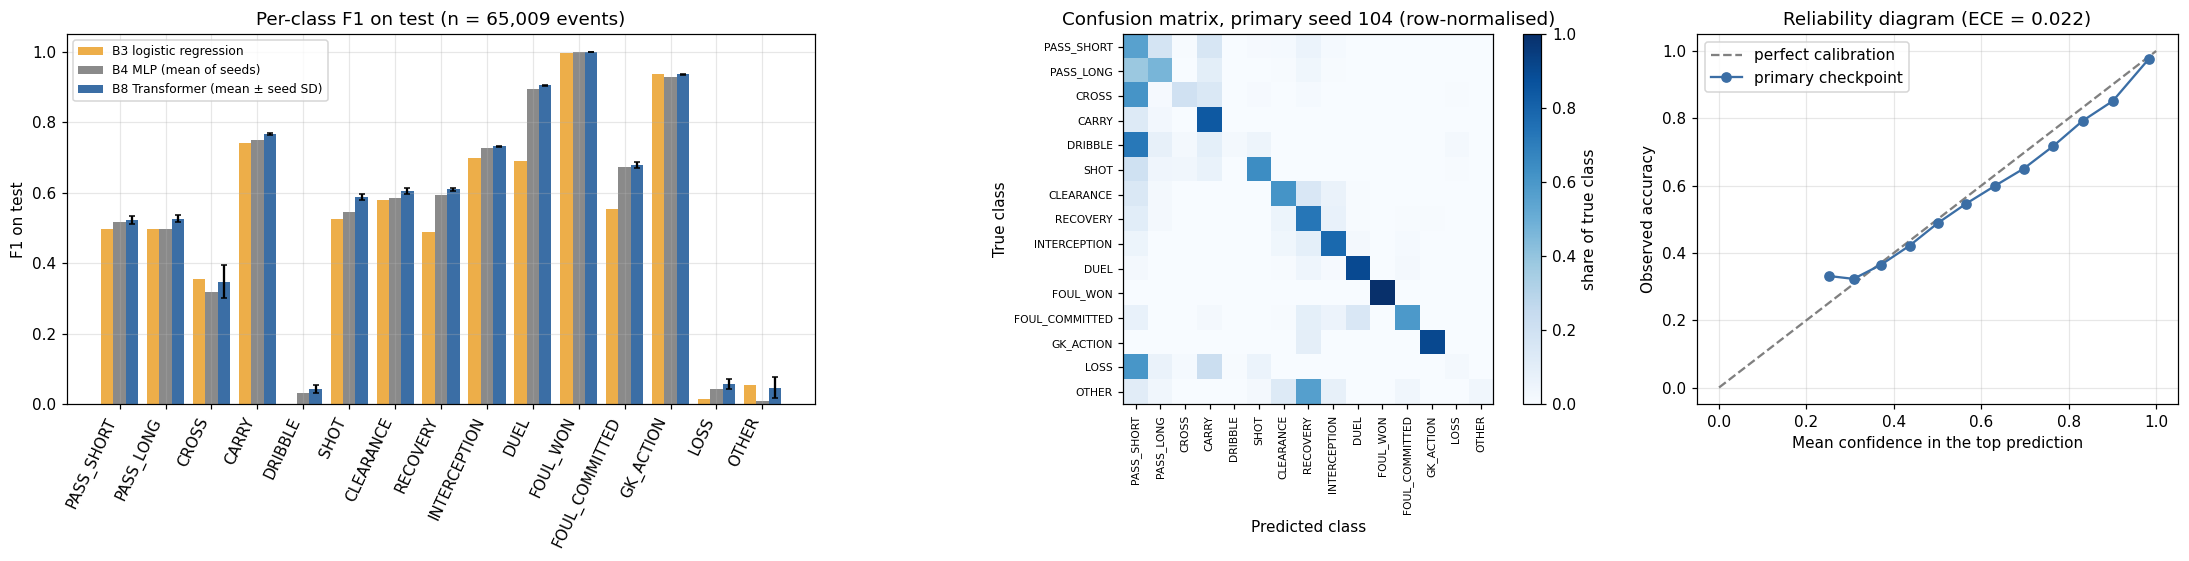

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2), gridspec_kw={"width_ratios": [1.4, 1.1, 0.9]})
positions = np.arange(15)
b8_per_class = np.array([metrics.compute_metrics(l, test_targets)["per_class_f1"] for l in test_logits["B8 Transformer (final)"]])
b3_per_class = np.array(metrics.compute_metrics(test_logits["B3 logistic regression"][0], test_targets)["per_class_f1"])
b4_per_class = np.array([metrics.compute_metrics(l, test_targets)["per_class_f1"] for l in test_logits["B4 MLP"]]).mean(axis=0)
axes[0].bar(positions - 0.27, b3_per_class, width=0.27, label="B3 logistic regression", color="#edae49")
axes[0].bar(positions, b4_per_class, width=0.27, label="B4 MLP (mean of seeds)", color="#8a8a8a")
axes[0].bar(positions + 0.27, b8_per_class.mean(axis=0), width=0.27, yerr=b8_per_class.std(axis=0, ddof=1),
            capsize=2, label="B8 Transformer (mean ± seed SD)", color="#3b6ea5")
axes[0].set_xticks(positions)
axes[0].set_xticklabels(data.ACTION_NAMES, rotation=65, ha="right")
axes[0].set_ylabel("F1 on test")
axes[0].set_title(f"Per-class F1 on test (n = {len(test_rows):,} events)")
axes[0].legend(fontsize=8)

confusion_matrix = metrics.confusion(primary_logits, test_targets).astype(float)
row_normalised = confusion_matrix / confusion_matrix.sum(axis=1, keepdims=True)
image = axes[1].imshow(row_normalised, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks(positions)
axes[1].set_xticklabels(data.ACTION_NAMES, rotation=90, fontsize=7)
axes[1].set_yticks(positions)
axes[1].set_yticklabels(data.ACTION_NAMES, fontsize=7)
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("True class")
axes[1].set_title(f"Confusion matrix, primary seed {primary_seed} (row-normalised)")
axes[1].grid(False)
fig.colorbar(image, ax=axes[1], fraction=0.046, label="share of true class")

probabilities = np.exp(metrics.log_softmax(primary_logits))
reliability = pd.DataFrame(metrics.reliability_table(probabilities, test_targets))
reliability = reliability[reliability["count"] > 0]
axes[2].plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")
axes[2].plot(reliability["mean_confidence"], reliability["accuracy"], marker="o", color="#3b6ea5", label="primary checkpoint")
axes[2].set_xlabel("Mean confidence in the top prediction")
axes[2].set_ylabel("Observed accuracy")
axes[2].set_title(f"Reliability diagram (ECE = {primary_metrics['ece']:.3f})")
axes[2].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_test_class_confusion_calibration.png", bbox_inches="tight")
plt.show()

**What the figure shows.** Left: F1 per action class on test for B3, B4 and the final Transformer (error bars: standard deviation over the five seeds). Middle: the row-normalised confusion matrix of the primary checkpoint (seed 104); row *i* shows how events of true class *i* were predicted. Right: the reliability diagram; events are grouped by the model's confidence in its top prediction, and points on the dashed line mean that the stated confidence equals the observed accuracy.

**Observation.**

* The Transformer's largest gains over logistic regression are on DUEL, RECOVERY, FOUL_COMMITTED and SHOT, i.e. actions whose likelihood depends on the preceding sequence (contests, loose balls, fouls following duels).
* DRIBBLE, LOSS and OTHER remain close to zero F1 for all models. The confusion matrix shows DRIBBLE and LOSS events predicted mostly as short passes or carries, and OTHER mostly as recoveries. PASS_LONG and CROSS are frequently predicted as PASS_SHORT.
* The reliability diagram lies close to the diagonal (ECE 0.022 for the primary checkpoint). Between confidences of about 0.5 and 0.95 the points lie slightly below the diagonal (slight over-confidence); in the lowest bins they lie above it.

**Interpretation.** The model separates actions that follow from the recent sequence well and fails on actions that are outcomes rather than choices visible before the action (losing the ball, beating a player). The short/long/cross confusion reflects decisions that depend on information not present in event data, such as the positions of other players. Calibration is good enough for the log-probabilities to be analysed directly; no post-hoc calibration is applied.

**Note.** FOUL_WON and the goalkeeper records after goals are near-deterministic for annotation reasons (notebook 01, Section 8); their high F1 is not modelling skill. Rare classes have few test events, so their F1 values are uncertain.

### 6.3 Stratified test performance

NLL of the final Transformer (per-event NLL averaged over the five seeds) in football-relevant subgroups, next to B7 (no player/team) and B3 (no sequence). Differences *between* subgroups partly reflect how hard each situation is, so the within-subgroup comparison between models is the informative quantity.

In [16]:
def mean_event_nll(model_name):
    return np.mean([metrics.per_event_nll(l, test_targets) for l in test_logits[model_name]], axis=0)

nll_b8 = mean_event_nll("B8 Transformer (final)")
nll_b7 = mean_event_nll("B7 role-only")
nll_b3 = mean_event_nll("B3 logistic regression")
strata = evaluation.stratum_labels(events)
strata["player frequency"] = player_band
strata["team status"] = team_status

stratified_rows = []
for stratum_name, labels in strata.items():
    test_labels = labels[test_rows]
    for group in sorted(set(test_labels)):
        mask = test_labels == group
        ci = metrics.match_bootstrap_mean(nll_b8[mask], test_match_ids[mask], n_resamples=1000 if RUN_MODE == "full" else 20)
        stratified_rows.append({"stratum": stratum_name, "group": group, "events": int(mask.sum()),
                                "B8 NLL": nll_b8[mask].mean(), "B8 95% CI": f"[{ci['ci_low']:.3f}, {ci['ci_high']:.3f}]",
                                "B7 role-only NLL": nll_b7[mask].mean(), "B3 NLL": nll_b3[mask].mean(),
                                "identity value (B7 - B8)": nll_b7[mask].mean() - nll_b8[mask].mean(),
                                "B8 accuracy (primary)": (primary_logits[mask].argmax(1) == test_targets[mask]).mean()})
stratified_table = pd.DataFrame(stratified_rows).set_index(["stratum", "group"])
stratified_table.round(4)

events  B8 NLL  \
stratum                group                                              
zone                   final third                        13052  1.0610   
                       middle third                       29032  0.9189   
                       opponent penalty box                2167  1.1270   
                       own third                          20758  0.7983   
time                   0-15'                              11318  0.9121   
                       15-30'                             10300  0.9217   
                       30-45'                             10075  0.9122   
                       45-60'                             11257  0.9302   
                       60-75'                              9631  0.9035   
                       75'+                               12428  0.9138   
score state            level                              32179  0.9170   
                       losing                             16263  0.9200   
                       winning                            16567  0.9095   
possession spell       early in spell (0-2)               18650  0.9097   
                       first event of period                 70  0.4092   
                       long spell (10+)                   20387  0.9111   
                       mid spell (3-9)                    25902  0.9254   
turnover of actor team acting team changed                16596  0.8208   
                       same acting team                   48413  0.9484   
coupled                genuine sequence event             58115  1.0046   
                       same-moment (coupled) event         6894  0.1680   
player frequency       100-299                            21686  0.9164   
                       300-999                            10816  0.9222   
                       <100 train events (incl. unseen)   29503  0.9182   
                       >=1000                              3004  0.8661   
team status            team seen in training              55845  0.9145   
                       team unseen in training             9164  0.9241   

                                                              B8 95% CI  \
stratum                group                                              
zone                   final third                       [1.034, 1.090]   
                       middle third                      [0.902, 0.935]   
                       opponent penalty box              [1.079, 1.175]   
                       own third                         [0.781, 0.816]   
time                   0-15'                             [0.892, 0.932]   
                       15-30'                            [0.903, 0.941]   
                       30-45'                            [0.896, 0.929]   
                       45-60'                            [0.908, 0.952]   
                       60-75'                            [0.882, 0.925]   
                       75'+                              [0.896, 0.931]   
score state            level                             [0.904, 0.929]   
                       losing                            [0.901, 0.937]   
                       winning                           [0.884, 0.935]   
possession spell       early in spell (0-2)              [0.891, 0.927]   
                       first event of period             [0.303, 0.514]   
                       long spell (10+)                  [0.893, 0.931]   
                       mid spell (3-9)                   [0.912, 0.937]   
turnover of actor team acting team changed               [0.798, 0.842]   
                       same acting team                  [0.935, 0.962]   
coupled                genuine sequence event            [0.988, 1.021]   
                       same-moment (coupled) event       [0.145, 0.190]   
player frequency       100-299                           [0.896, 0.933]   
                       300-999                           [0.890, 0.954]   
      

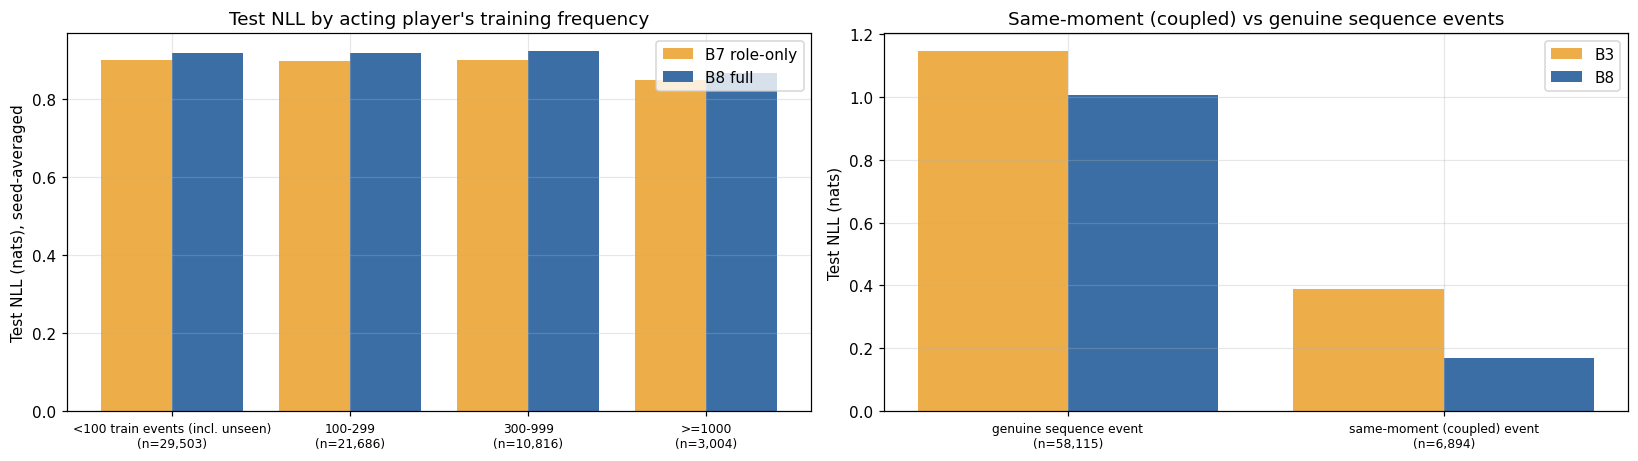

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
frequency_rows = stratified_table.loc["player frequency"]
order = ["<100 train events (incl. unseen)", "100-299", "300-999", ">=1000"]
order = [name for name in order if name in frequency_rows.index]
x_positions = np.arange(len(order))
axes[0].bar(x_positions - 0.2, frequency_rows.loc[order, "B7 role-only NLL"], width=0.4, label="B7 role-only", color="#edae49")
axes[0].bar(x_positions + 0.2, frequency_rows.loc[order, "B8 NLL"], width=0.4, label="B8 full", color="#3b6ea5")
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels([f"{name}\n(n={frequency_rows.loc[name, 'events']:,})" for name in order], fontsize=8)
axes[0].set_ylabel("Test NLL (nats), seed-averaged")
axes[0].set_title("Test NLL by acting player's training frequency")
axes[0].legend()

coupled_rows = stratified_table.loc["coupled"]
axes[1].bar(np.arange(len(coupled_rows)) - 0.2, coupled_rows["B3 NLL"], width=0.4, label="B3", color="#edae49")
axes[1].bar(np.arange(len(coupled_rows)) + 0.2, coupled_rows["B8 NLL"], width=0.4, label="B8", color="#3b6ea5")
axes[1].set_xticks(np.arange(len(coupled_rows)))
axes[1].set_xticklabels([f"{name}\n(n={coupled_rows.loc[name, 'events']:,})" for name in coupled_rows.index], fontsize=8)
axes[1].set_ylabel("Test NLL (nats)")
axes[1].set_title("Same-moment (coupled) vs genuine sequence events")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_test_stratified.png", bbox_inches="tight")
plt.show()

**What the figure shows.** Left: test NLL of the role-only model (B7) and the full model (B8) for groups of events defined by how often the acting player appears in training. Right: test NLL of logistic regression (B3) and B8 on same-moment ("coupled") events and on genuine sequence events.

**Observation.** B7 has lower test NLL than B8 in all four frequency groups, including the group of players with fewer than 100 training events, who have no dedicated embedding. The stratified table above shows the same direction in every other stratum (zone, time, score state, possession spell, turnover of the acting team, team status). Coupled events are far easier than genuine sequence events (B8 NLL 0.168 against 1.0046), and B8 is better than B3 in both groups.

**Interpretation.** The negative identity value is not specific to frequent players or to particular game situations; it appears throughout the test data. Across strata, NLL is lowest in the own third (0.7983) and highest in the opponent penalty box (1.1270), and events after a change of acting team (0.8208) are easier than events by the same team (0.9484). These differences describe how predictable the situations are, not a property of the identity inputs.

**What cannot be concluded.** Frequency groups differ in more than frequency (regular starters and substitutes, different competitions), so the pattern is descriptive, not causal.

In [18]:
genuine = strata["coupled"][test_rows] == "genuine sequence event"
robustness = {}
for model_name in ["B3 logistic regression", "B4 MLP", "B7 role-only", "B8 Transformer (final)"]:
    seed_values = [metrics.compute_metrics(l[genuine], test_targets[genuine]) for l in test_logits[model_name]]
    robustness[model_name] = {"NLL (genuine events only)": np.mean([m["nll"] for m in seed_values]),
                              "accuracy (genuine only)": np.mean([m["accuracy"] for m in seed_values]),
                              "macro-F1 (genuine only)": np.mean([m["macro_f1"] for m in seed_values])}
robustness_table = pd.DataFrame(robustness).T
print(f"Genuine sequence events: {genuine.sum():,} of {len(genuine):,} test events")
robustness_table.round(4)

Genuine sequence events: 58,115 of 65,009 test events


,NLL (genuine events only),accuracy (genuine only),macro-F1 (genuine only)
B3 logistic regression,1.1449,0.5370,0.4143
B4 MLP,1.0439,0.5632,0.4598
B7 role-only,0.9837,0.5861,0.4810
B8 Transformer (final),1.0046,0.5775,0.4763


**RESULT.** Without same-moment (coupled) events (58,115 of 65,009 test events), the test NLL is 1.1449 for logistic regression, 1.0439 for the MLP, 1.0046 for the full Transformer and 0.9837 for the role-only model. The ordering of the models is the same as on all events.

**Interpretation.** The conclusions above, including the negative identity value, do not depend on the annotation-coupled events. The genuine-event values are the more appropriate description of predictive skill on player decisions.

In [19]:
test_results = {
    "run_mode": RUN_MODE, "frozen_config": frozen, "primary_run": primary_run_name, "primary_seed": primary_seed,
    "n_test_events": int(len(test_rows)),
    "headline": headline_table.reset_index().to_dict(orient="records"),
    "primary_checkpoint_metrics": primary_metrics, "primary_macro_f1_ci": primary_f1_ci,
    "stratified": stratified_table.reset_index().to_dict(orient="records"),
    "robustness_genuine_events_only": robustness_table.reset_index().to_dict(orient="records"),
    "per_class_f1_b8_mean": b8_per_class.mean(axis=0).tolist(),
}
if not test_done_flag.exists():
    training.save_json(test_done_flag, test_results)
    print("Test results saved:", test_done_flag)
else:
    print("Test results were saved on the first evaluation and are not overwritten.")

Test results saved: /content/drive/MyDrive/soccer_mi/track_a/results/06_test_results.json


## 7. Summary

* The frozen configuration (2 layers, 2 heads, K = 16, T300) trains stably: five seeds reach validation NLL 0.9048–0.9077 (SD 0.0011).
* All validation gates pass. On test, the Transformer reaches NLL 0.9158, accuracy 0.6161, macro-F1 0.5580 and ECE 0.0238, and is better than all non-neural baselines and the MLP.
* The identity value is negative on validation (−0.0201) and on test (−0.0199): the role-only model predicts better than the full model, in every player-frequency group and stratum examined.
* DRIBBLE, LOSS and OTHER remain essentially unpredicted.

**Limitations.** One data source (StatsBomb open data), 350 matches, 35 test matches. The possession-feature correction (notebook 01) and the shuffled-control definition (notebook 02) are design decisions of this study. The identity results inherit the actor-selection caveat (the actor is partly determined by the event type). Predictive results do not describe the model's internal computation.